> **결함판(참고용)**: 이 노트북은 σ 전파 오류(GARCH·SV)와 드리프트 비교 조건 불일치가 있는 초기 파이프라인 결과다. 현재 기준은 상위 폴더의 `8-2`~`8-5`이고, 검증 내용은 `8-6(참고)`에 있다. 원본 출력은 그대로 보존했다(재실행 시 경로는 이 폴더 기준).

# 8-5. 로그변환 진단 (결함 버전 기준 -- 수정판 재확인은 8-9 참고)

> **참고**: 이 노트북의 GARCH·SV 수치는 `8-6`에서 발견한 결함(다단계 σ 과소 계산, 드리프트 비대칭)이 있는 파이프라인 위에서 계산했다. 로그 vs 원 스케일은 같은 구현끼리의 비교라 결론(로그변환 미채택)의 방향은 유지될 가능성이 크지만, 수정판으로 다시 확인한 결과는 새 `8-5` 참고(미채택 유지, 다만 σ 보정 효과는 AR단독뿐 아니라 세 모델 모두에서 나타남).

외부 피드백: "통계모델은 대개 잔차에 정규분포를 가정하니 로그변환을 시도해볼 만하다."

로그변환을 파이프라인에 넣기 전에 (1) 잔차가 정규분포인지 (2) 로그로 나아지는지 진단하고, (3) 로그 스케일에서 성능(커버리지·MSE·CRPS)도 직접 비교한다.


In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import pmdarima as pm
from arch import arch_model
from scipy import stats
from scipy.optimize import minimize

raw = pd.read_csv("../../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", "X3_l1"]].dropna()["X3_l1"].values.astype(float)
print(f"X3_l1: n={len(vals)}, 최소 {vals.min():.1f}, 최대 {vals.max():.1f} (전부 양수 -> 로그 가능)")


X3_l1: n=60, 최소 79.2, 최대 1305.8 (전부 양수 -> 로그 가능)


## 1. 차분값 비교

로그변환의 통상 근거는 (a) 정규분포에 가까워진다 (b) 수준이 클수록 변동이 커지는 패턴이 안정화된다 -- 둘이다. 모델 적합 전에 차분값으로 먼저 본다.

**JB p (Jarque-Bera 검정의 p-value)**: 왜도(좌우 비대칭)와 초과첨도(꼬리가 정규분포보다 두꺼운 정도)를 하나의 통계량으로 묶어 "잔차가 정규분포다"라는 가정을 검정한다. p는 "정말 정규분포라면 이만큼 치우치고 꼬리가 두꺼운 모양이 우연히 나올 확률"이다. **작으면(보통 0.05 미만) 정규분포가 아니라는 증거**이고, **크면 정규분포가 아니라는 증거가 없다**는 뜻이지 정규분포라고 증명된 것은 아니다. 표본이 작으면(n=58) 검정력이 낮고 극단값 몇 개에 민감하다.

**극단값 2개 제외**: 절대값이 가장 큰 표준화 잔차 2개(58개 중)를 뺀 뒤 다시 계산한 JB p다. 몸통은 정규분포에 가깝지만 소수의 큰 값 때문에 기각되는 것인지 확인하려는 것이다.


In [2]:
rows = []
for name, x in [("원 스케일 차분", np.diff(vals)), ("로그 차분", np.diff(np.log(vals)))]:
    rows.append({"차분": name, "왜도": stats.skew(x), "초과첨도": stats.kurtosis(x),
                 "JB p-value": stats.jarque_bera(x).pvalue,
                 "|차분|과 이전 수준의 상관": np.corrcoef(np.abs(x), vals[:-1])[0, 1]})
display(pd.DataFrame(rows).round(4))


,차분,왜도,초과첨도,JB p-value,|차분|과 이전 수준의 상관
0,원 스케일 차분,1.1457,2.6105,0.0,0.0830
1,로그 차분,1.3278,2.2178,0.0,-0.3977


## 2. 모델 잔차 비교 (세 모델 x 원/로그 스케일)

d=1, p=1(`8-4` 확정값)이라 차분한 시계열에 AR(1)을 적합한 것과 같다. 표준화 잔차는 AR단독은 전체 표준편차로, GARCH동시는 `arch`의 조건부 표준편차로, SV동시는 직전까지의 정보로 예측한 변동성으로 나눈다.


In [3]:
XI_MEAN, XI_VAR, MAX_PHI = -1.2704, np.pi ** 2 / 2, 0.97


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def joint_nll(params, y):
    ar, phi, s2 = params[0], MAX_PHI * np.tanh(params[1]), np.exp(params[2]) ** 2
    if abs(ar) >= 0.999:
        return 1e10
    z = np.log((y[1:] - ar * y[:-1]) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def ar_std_resid(y):
    m = pm.ARIMA(order=(1, 0, 0), with_intercept=False, suppress_warnings=True).fit(y)
    r = np.asarray(m.resid())[1:]  # 첫 관측치의 예측오차는 정상분포 초기화 때문에 성격이 달라 제외
    return r / r.std()


def garch_std_resid(y):
    # rescale=True: 로그 스케일처럼 값이 작을 때 최적화가 안 흔들리게 함 (표준화 잔차는 스케일과 무관)
    res = arch_model(y, mean="AR", lags=1, vol="GARCH", p=1, q=1, rescale=True).fit(disp="off")
    z = np.asarray(res.std_resid)
    return z[~np.isnan(z)]


def sv_std_resid(y):
    yd = y - y.mean()
    res = minimize(joint_nll, [0.0, 1.5, np.log(0.3)], args=(yd,), method="Nelder-Mead", options={"maxiter": 3000})
    ar, phi, s2 = res.x[0], MAX_PHI * np.tanh(res.x[1]), np.exp(res.x[2]) ** 2
    r = yd[1:] - ar * yd[:-1]
    z = np.log(r ** 2 + 1e-8)
    zm = z.mean()
    h, P, sig = 0.0, s2 / (1 - phi ** 2), []
    for x in z - zm:
        sig.append(np.sqrt(np.exp(zm - XI_MEAN + h + P / 2)))  # 직전까지 정보로 예측한 변동성
        K = P / (P + XI_VAR)
        hf, Pf = h + K * (x - h), P * (1 - K)
        h, P = phi * hf, phi ** 2 * Pf + s2
    return r / np.array(sig)


series = {"원 스케일": np.diff(vals), "로그 스케일": np.diff(np.log(vals))}
models = {"AR단독": ar_std_resid, "GARCH동시": garch_std_resid, "SV동시": sv_std_resid}
zs, rows = {}, []
for sname, y in series.items():
    for mname, fn in models.items():
        z = fn(y)
        zs[(sname, mname)] = z
        rows.append({"스케일": sname, "모델": mname, "n": len(z), "왜도": stats.skew(z),
                     "초과첨도": stats.kurtosis(z), "JB p-value": stats.jarque_bera(z).pvalue})
display(pd.DataFrame(rows).round(4))


,스케일,모델,n,왜도,초과첨도,JB p-value
0,원 스케일,AR단독,58,1.1234,3.6753,0.0000
1,원 스케일,GARCH동시,58,1.1056,3.9711,0.0000
2,원 스케일,SV동시,58,0.8795,1.6109,0.0010
3,로그 스케일,AR단독,58,2.0142,6.7651,0.0000
4,로그 스케일,GARCH동시,58,1.1367,3.1006,0.0000
5,로그 스케일,SV동시,58,0.8812,1.3300,0.0028


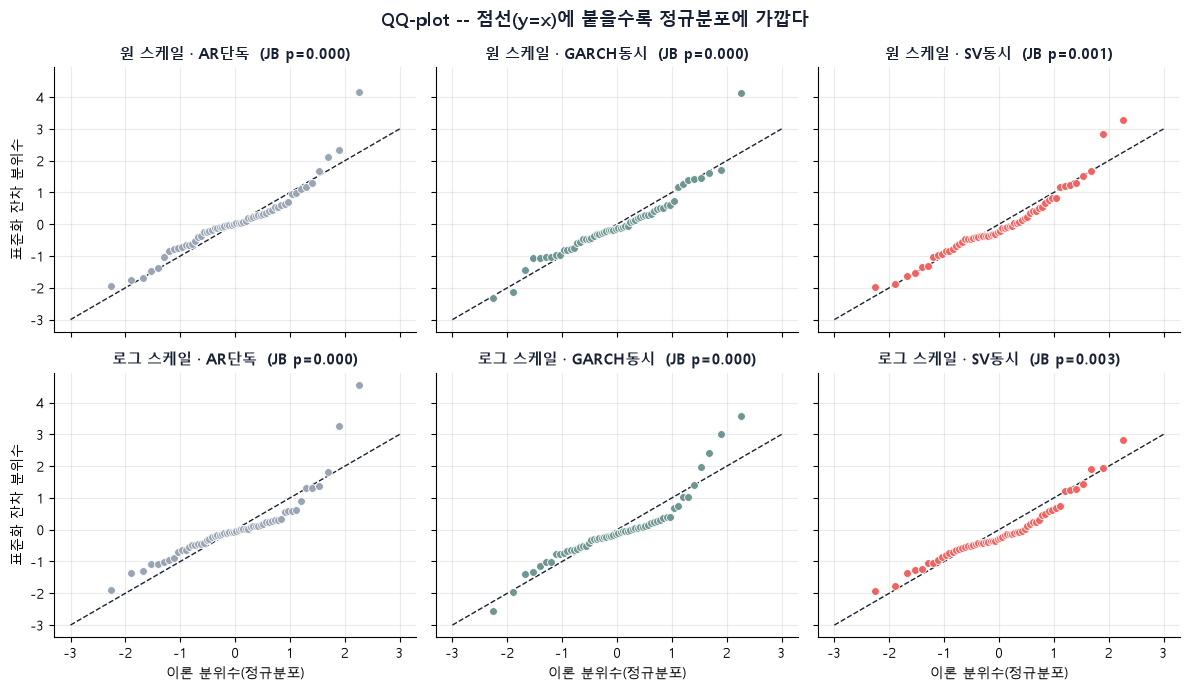

In [4]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

colors = {"AR단독": "#9AA5B4", "GARCH동시": "#6F9692", "SV동시": "#EF6461"}
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
for i, sname in enumerate(series):
    for j, mname in enumerate(models):
        ax, z = axes[i, j], zs[(sname, mname)]
        (osm, osr), _ = stats.probplot(z, dist="norm")
        ax.plot([-3, 3], [-3, 3], color="#172033", linestyle="--", linewidth=1)
        ax.scatter(osm, osr, s=32, color=colors[mname], edgecolor="white", linewidth=0.6, zorder=3)
        ax.set_title(f"{sname} · {mname}  (JB p={stats.jarque_bera(z).pvalue:.3f})", fontsize=11, fontweight="bold", color="#172033")
        ax.grid(alpha=0.25)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        if i == 1:
            ax.set_xlabel("이론 분위수(정규분포)")
        if j == 0:
            ax.set_ylabel("표준화 잔차 분위수")
fig.suptitle("QQ-plot -- 점선(y=x)에 붙을수록 정규분포에 가깝다", fontsize=13, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()


### 극단값 민감도

JB 기각이 몇 개의 극단값 때문인지, 절대값이 가장 큰 잔차 2개(58개 중)를 빼고 다시 검정한다.


In [5]:
rows = []
for (sname, mname), z in zs.items():
    keep = np.argsort(np.abs(z))[:-2]
    rows.append({"스케일": sname, "모델": mname, "JB p(전체)": stats.jarque_bera(z).pvalue,
                 "JB p(극단값 2개 제외)": stats.jarque_bera(z[keep]).pvalue,
                 "제외한 |z|": np.round(np.sort(np.abs(z))[-2:], 2).tolist()})
display(pd.DataFrame(rows).round(4))


,스케일,모델,JB p(전체),JB p(극단값 2개 제외),제외한 |z|
0,원 스케일,AR단독,0.0000,0.6777,"[2.35, 4.17]"
1,원 스케일,GARCH동시,0.0000,0.7465,"[2.32, 4.14]"
2,원 스케일,SV동시,0.0010,0.9427,"[2.83, 3.28]"
3,로그 스케일,AR단독,0.0000,0.4335,"[3.27, 4.56]"
4,로그 스케일,GARCH동시,0.0000,0.0029,"[3.0, 3.57]"
5,로그 스케일,SV동시,0.0028,0.0677,"[1.93, 2.82]"


## 3. 진단 소결

- **차분값(1절)**: 로그 차분도 정규분포에 가깝지 않고(왜도 1.15 -> 1.33), "수준이 클수록 변동이 커지는 패턴"도 원래 없다(상관 0.08).
- **원 스케일 잔차(2절)**: JB는 정규분포를 기각하지만(p≤0.001) **극단값 2개를 빼면 p가 0.68~0.94**다. 몸통은 정규분포에 가깝고 소수의 큰 값이 꼬리를 만든다.
- **로그 스케일**: AR단독은 나빠지고(왜도 1.12 -> 2.01), GARCH·SV동시는 거의 그대로이며, 극단값 2개를 빼도 GARCH동시는 여전히 기각된다(p=0.003). 정규성 개선 근거가 없다.
- 한계: in-sample, n=58이라 JB 검정력이 낮다.


## 4. 로그 스케일 파이프라인 비교

`로그 -> (차분) -> 학습·예측 -> 누적합 복원 -> exp 역변환`. 세 모델과 함수는 `8-4`와 같고 입력만 로그값(x100)이다.

- **d,p도 다시 고른다**: 로그를 취하면 d=1이 "성장률 차분"이 되어 최적 (d,p)가 바뀔 수 있으므로 9개 조합을 전부 다시 돌린다.
- **채점은 원 스케일**에서 하고 정규화도 `8-4`와 같아 수치가 직접 비교된다. 커버리지는 `exp`로 복원한 구간, MSE는 평균 `exp(μ+σ²/2)`(중앙값 `exp(μ)`도 참고), CRPS는 로그정규 닫힌형태 공식(수치적분으로 검증)을 쓴다.


In [6]:
import os
from scipy.integrate import quad

D_CANDIDATES, P_CANDIDATES = [0, 1, 2], [0, 1, 2]
MODEL_NAMES = ["AR단독", "GARCH동시", "SV동시"]
H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
var_std = vals.std()
origins = list(range(MIN_TRAIN, len(vals) - H + 1))
scored_origins = origins[INITIAL_CALIB:]


def difference(values, d):
    x = np.asarray(values, dtype=float)
    hist = []
    for _ in range(d):
        hist.append(x.copy())
        x = np.diff(x)
    return x, hist


def undiff_mean(diff_fc, hist, d):
    fc = np.asarray(diff_fc, dtype=float)
    for i in reversed(range(d)):
        fc = hist[i][-1] + np.cumsum(fc)
    return fc


def propagate_var(var_diff, d):
    v = np.array(var_diff, dtype=float)
    for _ in range(d):
        v = np.cumsum(v)
    return v


def is_ar_stable(ar_coefs):
    p = len(ar_coefs)
    if p == 0:
        return True
    companion = np.zeros((p, p))
    companion[0, :] = ar_coefs
    if p > 1:
        companion[1:, :-1] = np.eye(p - 1)
    return np.max(np.abs(np.linalg.eigvals(companion))) < 0.999


def joint_sv_negloglik(params, y_demeaned, p):
    ar_coefs = params[:p]
    phi = MAX_PHI * np.tanh(params[p])
    sigma_eta2 = np.exp(params[p + 1]) ** 2
    if not is_ar_stable(ar_coefs):
        return 1e10
    n = len(y_demeaned)
    resid = np.array([y_demeaned[t] - sum(ar_coefs[i] * y_demeaned[t - 1 - i] for i in range(p)) for t in range(p, n)])
    z = np.log(resid ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, sigma_eta2)


def fit_ar_alone(train, d, p):
    return pm.ARIMA(order=(p, d, 0), with_intercept=False, suppress_warnings=True).fit(train)


def fit_garch_joint(diff_train, p):
    if len(diff_train) <= p + 3:
        return None
    am = arch_model(diff_train, mean="Zero", vol="GARCH", p=1, q=1, rescale=False) if p == 0 else \
        arch_model(diff_train, mean="AR", lags=p, vol="GARCH", p=1, q=1, rescale=False)
    try:
        return am.fit(disp="off")
    except Exception:
        return None


def fit_sv_joint(y, p):
    y_mean = y.mean()
    y_dm = y - y_mean
    if len(y_dm) <= p + 3:
        return None
    x0 = [0.0] * p + [1.5, np.log(0.3)]
    res = minimize(joint_sv_negloglik, x0, args=(y_dm, p), method="Nelder-Mead", options={"maxiter": 3000})
    if not is_ar_stable(res.x[:p]) or res.fun >= 1e9:
        return None
    return res.x, y_mean


def sv_forecast_mean_sigma(y, p, params, y_mean, h=H):
    y_dm = y - y_mean
    ar_coefs = params[:p]
    phi = MAX_PHI * np.tanh(params[p])
    sigma_eta2 = np.exp(params[p + 1]) ** 2
    n = len(y_dm)
    resid = np.array([y_dm[t] - sum(ar_coefs[i] * y_dm[t - 1 - i] for i in range(p)) for t in range(p, n)])
    z = np.log(resid ** 2 + 1e-8)
    z_mean = z.mean()
    zc = z - z_mean
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred = 0.0, P0
    for zt in zc:
        F = P_pred + XI_VAR
        v = zt - h_pred
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    hist = list(y_dm[-p:]) if p > 0 else []
    mean_fc_dm = []
    for _ in range(h):
        pred = sum(ar_coefs[i] * hist[-1 - i] for i in range(p))
        mean_fc_dm.append(pred)
        hist.append(pred)
    drift = y_mean if p > 0 else 0.0
    mean_fc = np.array(mean_fc_dm) + drift
    variances = []
    for k in range(1, h + 1):
        h_mean_k = phi ** k * h_filt
        h_var_k = phi ** (2 * k) * P_filt + sigma_eta2 * sum(phi ** (2 * j) for j in range(k))
        variances.append(np.exp(z_mean - XI_MEAN + h_mean_k + h_var_k / 2))
    return mean_fc, np.sqrt(np.array(variances))


def lognormal_crps(y, mu, s):
    w = (np.log(y) - mu) / s
    m = np.exp(mu + s ** 2 / 2)
    return y * (2 * stats.norm.cdf(w) - 1) - 2 * m * (stats.norm.cdf(w - s) + stats.norm.cdf(s / np.sqrt(2)) - 1)


def lognormal_crps_numeric(y, mu, s):
    F = lambda x: stats.lognorm.cdf(x, s=s, scale=np.exp(mu))
    return quad(lambda x: F(x) ** 2, 0, y, limit=200)[0] + quad(lambda x: (F(x) - 1) ** 2, y, np.exp(mu + 10 * s), limit=200)[0]


print("로그정규 CRPS 닫힌형태 공식 검증(수치적분과 비교):")
for y, mu, s in [(600.0, 6.5, 0.4), (300.0, 6.5, 0.8), (1000.0, 6.4, 0.3)]:
    print(f"  y={y:.0f}, mu={mu}, s={s}: 닫힌형태 {lognormal_crps(y, mu, s):.4f} / 수치적분 {lognormal_crps_numeric(y, mu, s):.4f}")


로그정규 CRPS 닫힌형태 공식 검증(수치적분과 비교):
  y=600, mu=6.5, s=0.4: 닫힌형태 70.0547 / 수치적분 70.0547
  y=300, mu=6.5, s=0.8: 닫힌형태 252.9552 / 수치적분 252.9552
  y=1000, mu=6.4, s=0.3: 닫힌형태 277.2429 / 수치적분 277.2429


In [7]:
CACHE_PATH = "../../cache/cache_85_log_dp_grid_result_df.pkl"
LOG = 100 * np.log(vals)
fin = lambda x: float(x) if np.isfinite(x) else np.inf

if os.path.exists(CACHE_PATH):
    log_df = pd.read_pickle(CACHE_PATH)
    print(f"캐시에서 로드: {len(log_df)}행 (재계산 스킵)")
else:
    rows = []
    for d in D_CANDIDATES:
        for p in P_CANDIDATES:
            for origin in scored_origins:
                train, actual = LOG[:origin], vals[origin:origin + H]
                diff_train, hist = difference(train, d)

                try:
                    m_a = fit_ar_alone(train, d, p)
                    fc_a, conf_a = m_a.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
                    sig_a = (conf_a[:, 1] - conf_a[:, 0]) / (2 * Z)
                except Exception:
                    fc_a, sig_a = None, None

                res_g = fit_garch_joint(diff_train, p)
                if res_g is not None:
                    fcst = res_g.forecast(horizon=H, reindex=False)
                    fc_g = undiff_mean(fcst.mean.values[-1], hist, d)
                    sig_g = np.sqrt(propagate_var(fcst.variance.values[-1], d))
                else:
                    fc_g, sig_g = None, None

                best_s = fit_sv_joint(diff_train, p)
                if best_s is not None:
                    params_s, y_mean_s = best_s
                    mean_s, sig_s_diff = sv_forecast_mean_sigma(diff_train, p, params_s, y_mean_s, H)
                    fc_s = undiff_mean(mean_s, hist, d)
                    sig_s = np.sqrt(propagate_var(sig_s_diff ** 2, d))
                else:
                    fc_s, sig_s = None, None

                for name, fc_arr, sig_arr in zip(MODEL_NAMES, [fc_a, fc_g, fc_s], [sig_a, sig_g, sig_s]):
                    if fc_arr is None:
                        continue
                    mu = np.asarray(fc_arr) / 100
                    s = np.maximum(np.asarray(sig_arr), 1e-6) / 100
                    lo, hi = np.exp(mu - Z * s), np.exp(mu + Z * s)
                    rows.append({
                        "d": d, "p": p, "모델": name, "origin": origin,
                        "crps": fin(np.mean(lognormal_crps(actual, mu, s)) / var_std),
                        "cov": np.mean((lo <= actual) & (actual <= hi)) * 100,
                        "mse": fin(np.mean(((actual - np.exp(mu + s ** 2 / 2)) / var_std) ** 2)),
                        "mse_med": fin(np.mean(((actual - np.exp(mu)) / var_std) ** 2)),
                    })

    log_df = pd.DataFrame(rows)
    os.makedirs(os.path.dirname(CACHE_PATH), exist_ok=True)
    log_df.to_pickle(CACHE_PATH)
    print(f"새로 계산 후 캐시 저장: {len(log_df)}행")


캐시에서 로드: 594행 (재계산 스킵)


In [8]:
orig_df = pd.read_pickle("../../cache/cache_84_dp_grid_result_df.pkl")


def summarize(df, mse_col="mse"):
    return df.groupby(["d", "p", "모델"]).agg(커버리지=("cov", "mean"), MSE=(mse_col, "mean"), CRPS=("crps", "mean")).round(3)


cmp = summarize(orig_df).join(summarize(log_df), lsuffix="_원", rsuffix="_로그")
cmp["MSE_로그(중앙값)"] = summarize(log_df, "mse_med")["MSE"]
display(cmp)


커버리지_원  MSE_원  CRPS_원  커버리지_로그        MSE_로그  CRPS_로그  \
d p 모델                                                               
0 0 AR단독     63.636  8.806   1.849  100.000  5.645622e+11   10.420   
    GARCH동시  88.636  8.806   1.721  100.000  2.750222e+14   20.550   
    SV동시     30.682  8.806   2.043    0.000  8.784000e+00    2.670   
  1 AR단독     59.091  1.065   0.579   72.727  1.073000e+00    0.579   
    GARCH동시  70.455  1.026   0.587   64.773  1.126000e+00    0.660   
    SV동시     78.409  2.318   0.918   65.909  2.057000e+00    0.932   
  2 AR단독     63.636  1.158   0.593   77.273  1.646000e+00    0.648   
    GARCH동시  68.182  1.140   0.614   76.136  9.800000e-01    0.608   
    SV동시     75.000  2.498   0.980   61.364  2.070000e+00    0.948   
1 0 AR단독     59.091  1.040   0.579   72.727  1.089000e+00    0.581   
    GARCH동시  72.727  1.040   0.577   77.273  1.134000e+00    0.608   
    SV동시     73.864  1.040   0.548   78.409  1.048000e+00    0.577   
  1 AR단독     65.909  1.128   0.593   78.409  1.902000e+00    0.668   
    GARCH동시  65.909  1.114   0.604   70.455  1.722000e+00    0.665   
    SV동시     69.318  1.086   0.591   69.318  1.647000e+00    0.685   
  2 AR단독     68.182  1.076   0.577   71.591  1.996000e+00    0.695   
    GARCH동시  68.182  1.156   0.621   69.318  2.184000e+00    0.702   
    SV동시     67.045  1.082   0.592   64.773  1.554000e+00    0.683   
2 0 AR단독     63.636  2.625   0.891   72.727  9.662500e+01    1.628   
    GARCH동시  61.364  2.625   0.915   72.727  2.286670e+02    1.716   
    SV동시     50.000  2.625   0.974   68.182  5.183500e+01    1.572   
  1 AR단독     59.091  2.445   0.873   65.909  3.412100e+01    1.397   
    GARCH동시  62.500  2.531   0.881   71.591  7.920900e+01    1.445   
    SV동시     39.773  2.786   1.010   61.364  2.674400e+01    1.471   
  2 AR단독     55.682  2.205   0.839   65.909  1.882500e+01    1.252   
    GARCH동시  65.909  2.355   0.854   71.591  7.551000e+01    1.434   
    SV동시     39.773  2.897   1.036   51.136  2.893900e+01    1.522   

             MSE_로그(중앙값)  
d p 모델                    
0 0 AR단독           8.787  
    GARCH동시        8.787  
    SV동시           8.787  
  1 AR단독           1.039  
    GARCH동시        1.278  
    SV동시           2.565  
  2 AR단독           1.232  
    GARCH동시        1.203  
    SV동시           2.586  
1 0 AR단독           1.040  
    GARCH동시        1.040  
    SV동시           1.040  
  1 AR단독           1.326  
    GARCH동시        1.141  
    SV동시           1.333  
  2 AR단독           1.401  
    GARCH동시        1.369  
    SV동시           1.316  
2 0 AR단독          25.393  
    GARCH동시       25.393  
    SV동시          25.393  
  1 AR단독          13.359  
    GARCH동시       12.153  
    SV동시          16.958  
  2 AR단독           8.697  
    GARCH동시       11.209  
    SV동시          19.022

In [9]:
def rank_sum_table(summary_df):
    parts = []
    for model in MODEL_NAMES:
        sub = summary_df.xs(model, level="모델")
        parts.append(pd.DataFrame({"커버리지순위": (sub["커버리지"] - 90).abs().rank(), "MSE순위": sub["MSE"].rank(),
                                    "CRPS순위": sub["CRPS"].rank()}))
    rs = sum(parts)
    rs["합계"] = rs.sum(axis=1)
    return rs.sort_values("합계")


orig_sum = summarize(orig_df).rename(columns=str)
log_sum = summarize(log_df)
print("원 스케일 순위 합산 (8-4와 동일):")
display(rank_sum_table(orig_sum))
print("\n로그 스케일 순위 합산:")
display(rank_sum_table(log_sum))


원 스케일 순위 합산 (8-4와 동일):


커버리지순위  MSE순위  CRPS순위    합계
d p                             
1 0    12.0    4.0     4.5  20.5
0 1    11.0    7.0     8.5  26.5
1 2    10.5   10.0     9.0  29.5
  1    12.5   10.0     9.5  32.0
0 2    10.5   14.0    14.5  39.0
2 0    19.0   22.0    21.0  62.0
  2    23.0   20.0    20.0  63.0
  1    22.5   21.0    21.0  64.5
0 0    14.0   27.0    27.0  68.0


로그 스케일 순위 합산:


커버리지순위  MSE순위  CRPS순위    합계
d p                             
1 0     8.0    6.0     4.5  18.5
0 2    12.5    9.0     9.5  31.0
  1    18.0    7.0     8.0  33.0
1 1    11.0   11.0    11.0  33.0
  2    20.0   12.0    12.0  44.0
2 0    12.0   25.0    24.0  61.0
  2    22.0   20.0    19.0  61.0
  1    20.5   21.0    20.0  61.5
0 0    11.0   24.0    27.0  62.0

## 5. 예측오차(z) 진단 (out-of-sample)

`z = (실측 - 예측) / 모델이 낸 σ` (d=1, p=1, 22개 origin x h=1~4 = 88개). σ가 맞다면 z는 표준정규분포(표준편차 1, |z| 중앙값 0.67, |z|>1.645 비율 10%)를 따른다. 로그 스케일은 `(log 실측 - μ) / s`로 계산한다. **σ 배율** = |z|의 90분위 / 1.645로, 90% 구간을 맞추려면 σ를 몇 배로 키워야 하는지 뜻한다. 88개는 서로 겹쳐 독립이 아니라서 JB 검정은 하지 않는다.


In [10]:
def walk_forward_z(series, scale_name, d=1, p=1):
    rows = []
    for origin in scored_origins:
        train, actual = series[:origin], vals[origin:origin + H]
        diff_train, hist = difference(train, d)
        out = {}
        m_a = fit_ar_alone(train, d, p)
        fc_a, conf_a = m_a.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
        out["AR단독"] = (np.asarray(fc_a), (conf_a[:, 1] - conf_a[:, 0]) / (2 * Z))
        fcst = fit_garch_joint(diff_train, p).forecast(horizon=H, reindex=False)
        out["GARCH동시"] = (undiff_mean(fcst.mean.values[-1], hist, d), np.sqrt(propagate_var(fcst.variance.values[-1], d)))
        params_s, y_mean_s = fit_sv_joint(diff_train, p)
        mean_s, sig_s = sv_forecast_mean_sigma(diff_train, p, params_s, y_mean_s, H)
        out["SV동시"] = (undiff_mean(mean_s, hist, d), np.sqrt(propagate_var(sig_s ** 2, d)))
        for name, (fc, sig) in out.items():
            for h in range(H):
                target = actual[h] if scale_name == "원 스케일" else 100 * np.log(actual[h])
                rows.append({"스케일": scale_name, "모델": name, "origin": origin, "h": h + 1,
                             "z": (target - fc[h]) / max(sig[h], 1e-6)})
    return pd.DataFrame(rows)


z_df = pd.concat([walk_forward_z(vals, "원 스케일"), walk_forward_z(LOG, "로그 스케일")], ignore_index=True)


def z_summary(g):
    z = g["z"].values
    a = np.abs(z)
    return pd.Series({"n": len(z), "z 표준편차": z.std(), "|z| 중앙값": np.median(a), "|z|>1.645 비율(%)": 100 * np.mean(a > Z),
                      "커버리지(%)": 100 * np.mean(a <= Z), "σ 배율": np.quantile(a, 0.9) / Z,
                      "왜도": stats.skew(z), "초과첨도": stats.kurtosis(z)})


z_tab = z_df.groupby(["스케일", "모델"]).apply(z_summary).round(2)
display(z_tab)
print("예측분포가 맞다면: z 표준편차 1, |z| 중앙값 0.67, |z|>1.645 비율 10%, 커버리지 90%, σ 배율 1, 왜도·초과첨도 0")
print("\nh별 z 표준편차:")
display(z_df.groupby(["스케일", "모델", "h"])["z"].std().unstack("h").round(2))


n  z 표준편차  |z| 중앙값  |z|>1.645 비율(%)  커버리지(%)  σ 배율    왜도  \
스케일    모델                                                                     
로그 스케일 AR단독     88.0    1.38     0.60            21.59    78.41  1.35  1.04   
       GARCH동시  88.0    1.92     0.57            29.55    70.45  2.25  0.28   
       SV동시     88.0    1.63     0.86            30.68    69.32  1.84 -0.07   
원 스케일  AR단독     88.0    2.10     1.22            34.09    65.91  1.80  1.10   
       GARCH동시  88.0    2.44     1.01            34.09    65.91  2.43  0.98   
       SV동시     88.0    1.81     1.04            30.68    69.32  1.85  0.67   

                초과첨도  
스케일    모델             
로그 스케일 AR단독     1.05  
       GARCH동시  0.69  
       SV동시    -0.13  
원 스케일  AR단독     1.27  
       GARCH동시  1.76  
       SV동시     0.69

예측분포가 맞다면: z 표준편차 1, |z| 중앙값 0.67, |z|>1.645 비율 10%, 커버리지 90%, σ 배율 1, 왜도·초과첨도 0

h별 z 표준편차:


h                  1     2     3     4
스케일    모델                             
로그 스케일 AR단독     1.60  1.48  1.35  1.20
       GARCH동시  1.78  2.04  2.02  2.02
       SV동시     1.34  1.67  1.80  1.82
원 스케일  AR단독     2.11  2.19  2.18  2.11
       GARCH동시  2.07  2.51  2.65  2.68
       SV동시     1.52  1.85  1.97  2.03

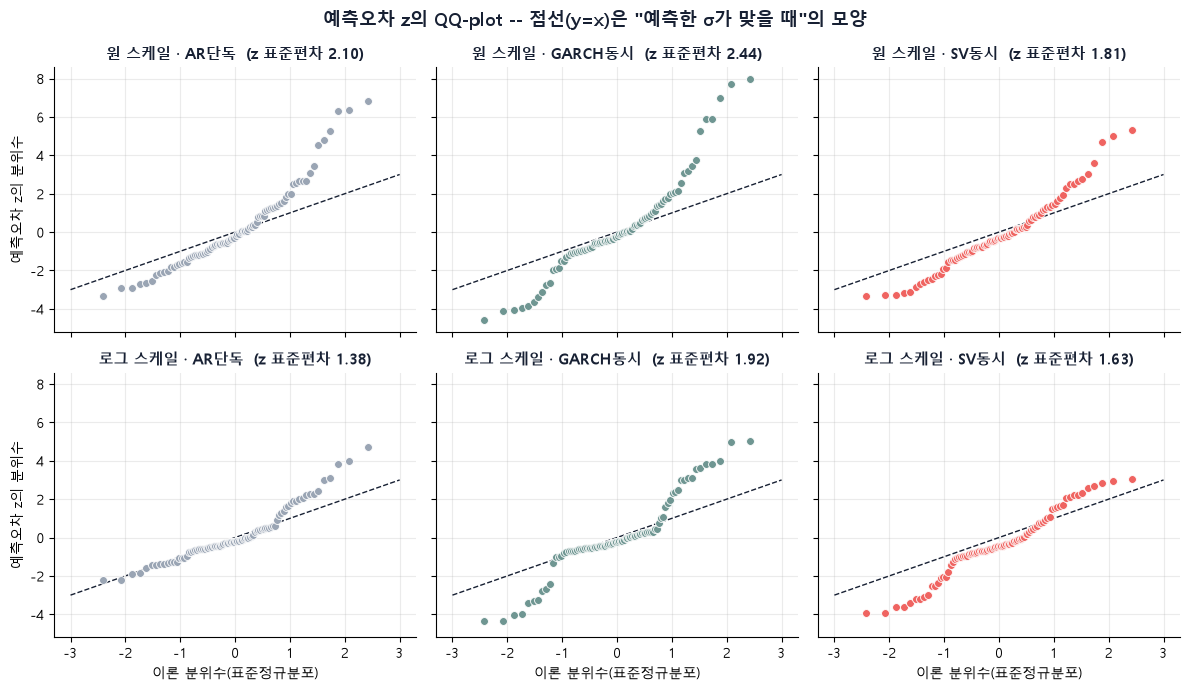

In [11]:
colors = {"AR단독": "#9AA5B4", "GARCH동시": "#6F9692", "SV동시": "#EF6461"}
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
for i, sname in enumerate(["원 스케일", "로그 스케일"]):
    for j, mname in enumerate(models):
        ax = axes[i, j]
        z = z_df[(z_df["스케일"] == sname) & (z_df["모델"] == mname)]["z"].values
        (osm, osr), _ = stats.probplot(z, dist="norm")
        ax.plot([-3, 3], [-3, 3], color="#172033", linestyle="--", linewidth=1)
        ax.scatter(osm, osr, s=32, color=colors[mname], edgecolor="white", linewidth=0.6, zorder=3)
        ax.set_title(f"{sname} · {mname}  (z 표준편차 {z.std():.2f})", fontsize=11, fontweight="bold", color="#172033")
        ax.grid(alpha=0.25)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        if i == 1:
            ax.set_xlabel("이론 분위수(표준정규분포)")
        if j == 0:
            ax.set_ylabel("예측오차 z의 분위수")
fig.suptitle("예측오차 z의 QQ-plot -- 점선(y=x)은 \"예측한 σ가 맞을 때\"의 모양", fontsize=13, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()


In [12]:
conc = z_df.assign(z2=z_df["z"] ** 2).groupby(["스케일", "모델", "origin"])["z2"].sum().reset_index()


def top5_share(g):
    s = g.sort_values("z2", ascending=False)
    return pd.Series({"상위 5개 origin의 z² 비중(%)": 100 * s["z2"].head(5).sum() / s["z2"].sum(), "상위 origin": list(s["origin"].head(5))})


display(conc.groupby(["스케일", "모델"]).apply(top5_share))


상위 5개 origin의 z² 비중(%)             상위 origin
스케일    모델                                                   
로그 스케일 AR단독                  73.740106  [47, 42, 38, 46, 41]
       GARCH동시               82.367384  [42, 38, 47, 35, 41]
       SV동시                  64.016842  [38, 37, 47, 39, 42]
원 스케일  AR단독                  72.382561  [47, 46, 35, 38, 48]
       GARCH동시               81.727729  [47, 46, 35, 38, 42]
       SV동시                  68.159591  [47, 38, 35, 48, 37]

**결과**

- **원 스케일**: z 표준편차 1.8~2.4, |z| 중앙값 1.0~1.2, 커버리지 65.9~69.3%. 모델이 낸 σ가 실제 오차의 절반 수준이고(σ 배율 1.8~2.4), h=1에서도 그렇다.
- **큰 오차는 소수 구간에 집중**: 상위 5개 origin(22개 중)이 z² 합의 64~82%를 차지한다(주로 예측구간 2019Q4~2021Q2, 2022Q3~2023Q4).
- **로그 스케일**: AR단독만 좋아지고(σ 배율 1.80 -> 1.35, 커버리지 65.9 -> 78.4%) GARCH(2.43 -> 2.25)·SV(1.85 -> 1.84)는 거의 그대로다. SV는 로그 스케일에서 z의 모양은 정규분포에 가깝지만 σ가 1.84배 작다 -- 문제는 모양이 아니라 σ의 크기다.
- **h별 패턴**: AR단독의 z 표준편차는 h와 무관하게 평탄한데(2.11 -> 2.11) GARCH·SV는 h에 따라 커진다(2.07 -> 2.68, 1.52 -> 2.03).

### σ 전파 검증

GARCH·SV는 차분의 단계별 분산을 `propagate_var`(누적합)로 수준의 σ로 바꾼다. 차분에 자기상관(φ)이 있으면 단계 간 오차가 상관돼 있어 누적합은 σ를 과소 계산한다. AR단독은 `pmdarima`가 정확한 σ를 준다. 같은 φ, σ_ε으로 정확한 공식과 누적합을 비교한다.


In [13]:
def level_sigma_check(origin):
    m = pm.ARIMA(order=(1, 1, 0), with_intercept=False, suppress_warnings=True).fit(vals[:origin])
    _, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    s_pm = (conf[:, 1] - conf[:, 0]) / (2 * Z)
    phi, s2 = float(m.params()[0]), float(m.params()[-1])
    exact = [np.sqrt(s2 * sum(sum(phi ** j for j in range(h - i + 1)) ** 2 for i in range(1, h + 1))) for h in range(1, H + 1)]
    cums = [np.sqrt(s2 * sum(sum(phi ** (2 * j) for j in range(k)) for k in range(1, h + 1))) for h in range(1, H + 1)]
    return phi, s_pm, np.array(exact), np.array(cums)


rows = []
for o in [scored_origins[0], scored_origins[-1]]:
    phi, s_pm, exact, cums = level_sigma_check(o)
    for h in range(H):
        rows.append({"origin": o, "φ": round(phi, 3), "h": h + 1, "pmdarima σ_h": round(s_pm[h], 1),
                     "정확한 공식 σ_h": round(exact[h], 1), "누적합 σ_h": round(cums[h], 1), "누적합/정확": round(cums[h] / exact[h], 3)})
display(pd.DataFrame(rows))


,origin,φ,h,pmdarima σ_h,정확한 공식 σ_h,누적합 σ_h,누적합/정확
0,35,0.546,1,50.6,50.6,50.6,1.000
1,35,0.546,2,93.2,93.2,76.8,0.823
2,35,0.546,3,132.0,132.0,97.2,0.737
3,35,0.546,4,166.6,166.6,114.4,0.687
4,56,0.515,1,89.0,89.0,89.0,1.000
5,56,0.515,2,161.5,161.5,133.9,0.829
6,56,0.515,3,226.2,226.2,168.8,0.746
7,56,0.515,4,283.2,283.2,198.0,0.699


누적합은 φ≈0.5에서 h=2,3,4의 σ를 정확한 값보다 약 17~18%, 25~26%, 30~31% 작게 만든다. GARCH동시(φ≈0.42)는 영향이 크고 SV동시(φ≈0)는 작다. 이 함수는 `8-2`~`8-4`의 GARCH·SV가 공유하므로 영향은 `8-6`에서 확인한다.


## 6. 결론

**로그변환은 채택하지 않는다.**

`8-4` 확정값(d=1, p=1) 기준 (원 스케일 -> 로그 스케일):

| 모델 | 커버리지(%) | MSE (로그: 평균 보정 / 중앙값) | CRPS |
|---|---|---|---|
| AR단독 | 65.9 -> 78.4 | 1.128 -> 1.902 / 1.326 | 0.593 -> 0.668 |
| GARCH동시 | 65.9 -> 70.5 | 1.114 -> 1.722 / 1.141 | 0.604 -> 0.665 |
| SV동시 | 69.3 -> 69.3 | 1.086 -> 1.647 / 1.333 | 0.591 -> 0.685 |

- **정확도는 나빠진다**: CRPS가 세 모델 모두 나빠지고, MSE도 원 스케일이 같거나 낫다.
- **커버리지는 AR단독·GARCH동시만 올랐고** 최고 78.4%로 목표 90%에 못 미친다. CRPS가 함께 나빠져서 예측분포가 좋아진 것은 아니다.
- **커버리지가 낮은 직접적 원인은 정규성이 아니라 σ의 크기**다(z 표준편차 1.8~2.4). 큰 오차는 소수 구간에 집중돼 있고 구조변화 가설이 유력하나 확인하지는 않았다.
- **최적 (d,p)는 그대로**: 로그 스케일 1위는 p=0 함정(d=1,p=0)이고, 이를 빼면 d=0 조합이 앞서지만 d=0에서 SV동시가 다시 불안정해 `8-4`와 같은 판단으로 d=1, p=1이 유지된다.
- **발견한 코드 한계**: GARCH·SV의 `propagate_var`가 h=2~4의 σ를 17~31% 과소 계산한다(5절). AR단독과 σ 계산 방식이 달라 모델 간 비교에 영향을 줄 수 있어 `8-6`에서 확인한다.
- 22개 origin의 통계적 유의성은 `8-4` 6절과 같은 한계로 검증하지 않았다.
